In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

ZOMATO_PATH = (
    BASE_PATH +
    "/datasets/raw/zomato/zomato_cleaned_dataset.csv"
)

MODEL_PATH = BASE_PATH + "/models/travel_time"
REPORT_PATH = BASE_PATH + "/reports/travel_time"

os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Dataset exists:", os.path.exists(ZOMATO_PATH))

Dataset exists: True


In [ ]:
df = pd.read_csv(ZOMATO_PATH)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (38964, 22)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow


In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_orderd', 'time_order_picked', 'weather_conditions', 'road_traffic_density', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'time_taken_min', 'distance_km', 'delivery_speed']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38964 entries, 0 to 38963
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           38964 non-null  object 
 1   delivery_person_id           38964 non-null  object 
 2   delivery_person_age          37945 non-null  float64
 3   delivery_person_ratings      37909 non-null  float64
 4   restaurant_latitude          38964 non-null  float64
 5   restaurant_longitude         38964 non-null  float64
 6   delivery_location_latitude   38964 non-null  float64
 7   delivery_location_longitude  38964 non-null  float64
 8   order_date                   38964 non-null  object 
 9   time_orderd                  38129 non-null  object 
 10  time_order_picked            38964 non-null  object 
 11  weather_conditions           38964 non-null  object 
 12  road_traffic_density         38964 non-null  object 
 13  vehicle_conditio

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,38964,38964,0xcdcd,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_person_id,38964,1170,HYDRES04DEL02,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_person_age,37945.0,NaN,NaN,NaN,29.607089,5.763202,20.0,25.0,30.0,35.0,39.0
delivery_person_ratings,37909.0,NaN,NaN,NaN,4.631879,0.317006,2.5,4.5,4.7,4.9,5.0
restaurant_latitude,38964.0,NaN,NaN,NaN,18.915583,5.460635,9.957144,12.986047,19.065838,22.751234,30.914057
restaurant_longitude,38964.0,NaN,NaN,NaN,76.914536,3.498179,72.768726,73.897902,76.618203,78.368855,88.433452
delivery_location_latitude,38964.0,NaN,NaN,NaN,18.979545,5.462504,9.967144,13.066047,19.124049,22.820072,31.054057
delivery_location_longitude,38964.0,NaN,NaN,NaN,76.978498,3.498357,72.778726,73.938972,76.663067,78.405467,88.563452
order_date,38964,44,15-03-2022,1031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_orderd,38129,176,17:55,407,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Target column exists:", "time_taken_min" in df.columns)

if "time_taken_min" not in df.columns:
    raise ValueError("Target column time_taken_min not found!")

Target column exists: True


In [ ]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_values.sort_values(
    by="Missing_Percentage",
    ascending=False
))

missing_values.to_csv(
    REPORT_PATH + "/missing_values_report.csv"
)

,Missing_Count,Missing_Percentage
delivery_person_ratings,1055,2.71
delivery_person_age,1019,2.62
time_orderd,835,2.14
delivery_person_id,0,0.00
restaurant_latitude,0,0.00
id,0,0.00
restaurant_longitude,0,0.00
delivery_location_latitude,0,0.00
delivery_location_longitude,0,0.00
order_date,0,0.00


In [ ]:
columns_to_drop = [
    "id",
    "delivery_person_id",
    "delivery_speed"
]

df = df.drop(
    columns=[
        col for col in columns_to_drop
        if col in df.columns
    ]
)

print("Shape after dropping unnecessary columns:", df.shape)

Shape after dropping unnecessary columns: (38964, 19)


In [ ]:
numeric_columns = [
    "delivery_person_age",
    "delivery_person_ratings",
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude",
    "vehicle_condition",
    "multiple_deliveries",
    "time_taken_min",
    "distance_km"
]

for col in numeric_columns:

    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

print("Numeric conversion completed.")

Numeric conversion completed.


In [ ]:
df = df.dropna(subset=["time_taken_min"])

# Remove impossible or clearly invalid target values
df = df[
    (df["time_taken_min"] > 0) &
    (df["time_taken_min"] < 180)
].copy()

print("Shape after target cleaning:", df.shape)

Shape after target cleaning: (38964, 19)


In [ ]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after:", df.duplicated().sum())
print("Final shape:", df.shape)

Duplicates before: 0
Duplicates after: 0
Final shape: (38964, 19)


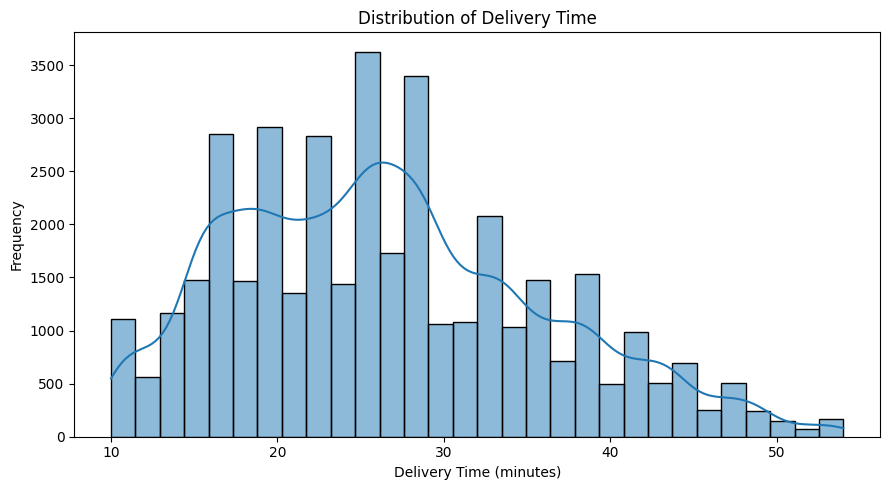

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["time_taken_min"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/delivery_time_distribution.png",
    dpi=300
)

plt.show()

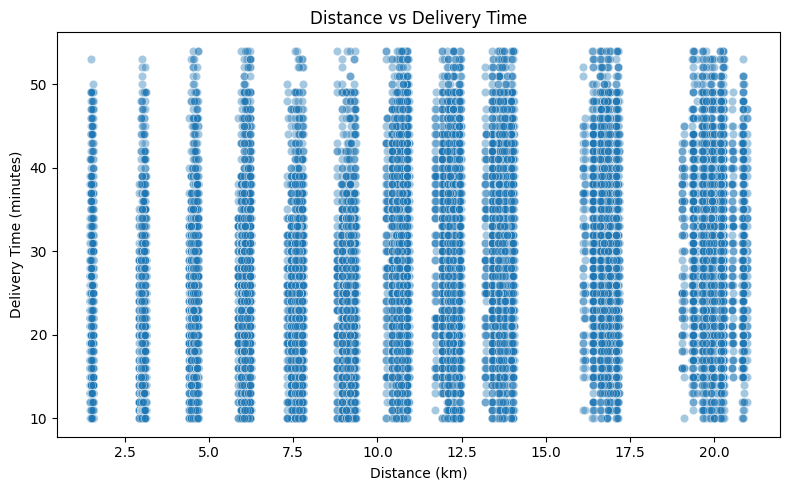

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="time_taken_min",
    alpha=0.4
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/distance_vs_delivery_time.png",
    dpi=300
)

plt.show()

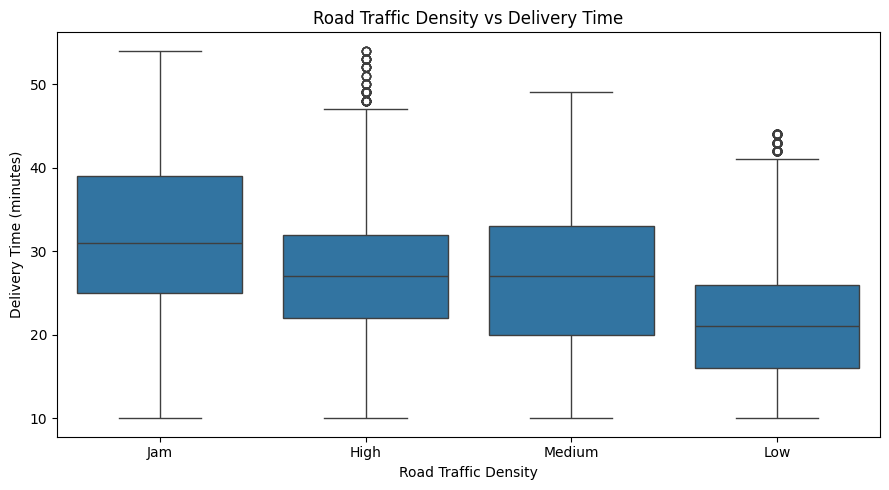

In [ ]:
if "road_traffic_density" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x="road_traffic_density",
        y="time_taken_min"
    )

    plt.title("Road Traffic Density vs Delivery Time")
    plt.xlabel("Road Traffic Density")
    plt.ylabel("Delivery Time (minutes)")

    plt.tight_layout()

    plt.savefig(
        REPORT_PATH + "/traffic_vs_delivery_time.png",
        dpi=300
    )

    plt.show()

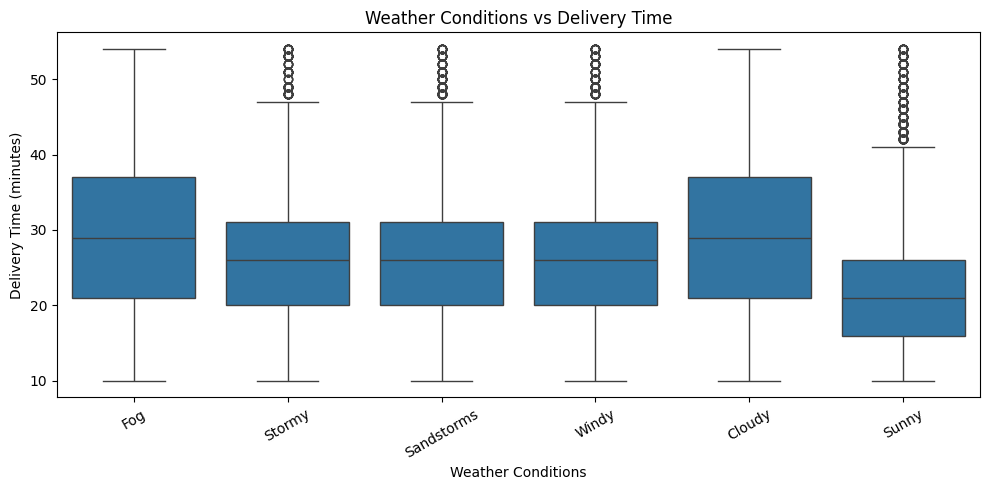

In [ ]:
if "weather_conditions" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x="weather_conditions",
        y="time_taken_min"
    )

    plt.title("Weather Conditions vs Delivery Time")
    plt.xlabel("Weather Conditions")
    plt.ylabel("Delivery Time (minutes)")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.savefig(
        REPORT_PATH + "/weather_vs_delivery_time.png",
        dpi=300
    )

    plt.show()

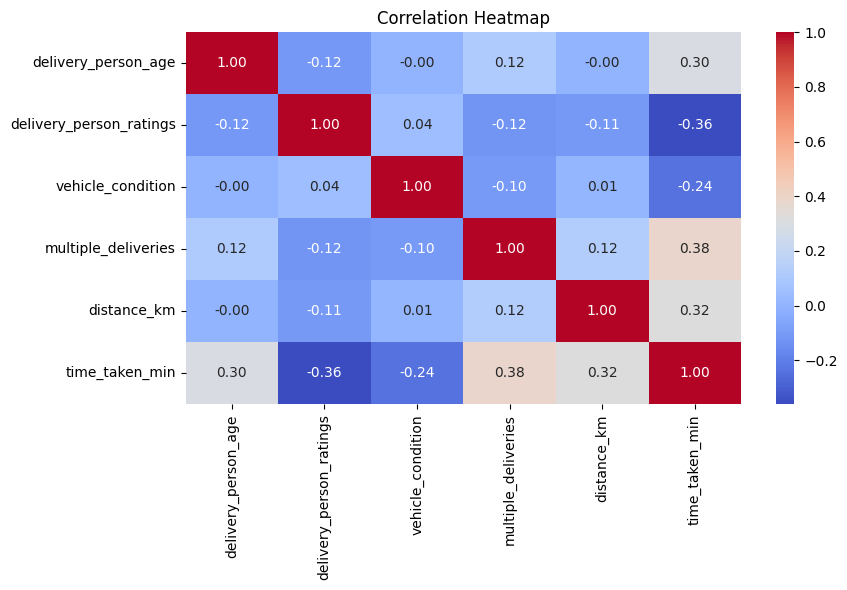

In [ ]:
correlation_columns = [
    "delivery_person_age",
    "delivery_person_ratings",
    "vehicle_condition",
    "multiple_deliveries",
    "distance_km",
    "time_taken_min"
]

available_columns = [
    col for col in correlation_columns
    if col in df.columns
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[available_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/correlation_heatmap.png",
    dpi=300
)

plt.show()

In [ ]:
if "time_orderd" in df.columns:

    df["order_hour"] = pd.to_datetime(
        df["time_orderd"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour

elif "time_ordered" in df.columns:

    df["order_hour"] = pd.to_datetime(
        df["time_ordered"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour

else:

    df["order_hour"] = np.nan

print(df["order_hour"].describe())

count    34619.000000
mean        17.583581
std          4.497272
min          8.000000
25%         15.000000
50%         19.000000
75%         21.000000
max         23.000000
Name: order_hour, dtype: float64


In [ ]:
if "order_date" in df.columns:

    df["order_date"] = pd.to_datetime(
        df["order_date"],
        errors="coerce",
        dayfirst=True
    )

    df["day_of_week"] = df["order_date"].dt.dayofweek

else:

    df["day_of_week"] = np.nan

display(df[["order_hour", "day_of_week"]].head())

,order_hour,day_of_week
0,21.0,5
1,14.0,6
2,17.0,4
3,9.0,6
4,19.0,0


In [ ]:
def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371  # Earth radius in kilometres

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) *
        np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [ ]:
required_coordinates = [
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude"
]

if all(col in df.columns for col in required_coordinates):

    df["geo_distance_km"] = haversine_distance(
        df["restaurant_latitude"],
        df["restaurant_longitude"],
        df["delivery_location_latitude"],
        df["delivery_location_longitude"]
    )

    print("Geographical distance calculated!")

display(
    df[["distance_km", "geo_distance_km"]].head()
)

Geographical distance calculated!


,distance_km,geo_distance_km
0,10.280582,10.280582
1,6.242319,6.242319
2,13.787860,13.787860
3,2.930258,2.930258
4,19.396618,19.396618


In [ ]:
categorical_columns = [
    "weather_conditions",
    "road_traffic_density",
    "type_of_order",
    "type_of_vehicle",
    "city",
    "festival"
]

for col in categorical_columns:

    if col in df.columns:

        print("\n", col)

        display(df[col].value_counts(dropna=False))


 weather_conditions


,count
weather_conditions,
Fog,6660
Stormy,6572
Cloudy,6563
Sandstorms,6489
Windy,6436
Sunny,6244



 road_traffic_density


,count
road_traffic_density,
Low,13139
Jam,12414
Medium,9556
High,3855



 type_of_order


,count
type_of_order,
Snack,9815
Meal,9774
Drinks,9751
Buffet,9624


... (2 outputs left out)


 city


,count
city,
Metropolitian,30036
Urban,8782
Semi-Urban,146



 festival


,count
festival,
No,38180
Yes,784


In [ ]:
candidate_features = [
    "distance_km",
    "geo_distance_km",
    "delivery_person_age",
    "delivery_person_ratings",
    "vehicle_condition",
    "multiple_deliveries",
    "weather_conditions",
    "road_traffic_density",
    "type_of_order",
    "type_of_vehicle",
    "city",
    "festival",
    "order_hour",
    "day_of_week"
]

features = [
    col for col in candidate_features
    if col in df.columns
]

target = "time_taken_min"

print("Selected features:")
print(features)

print("\nTarget:", target)

Selected features:
['distance_km', 'geo_distance_km', 'delivery_person_age', 'delivery_person_ratings', 'vehicle_condition', 'multiple_deliveries', 'weather_conditions', 'road_traffic_density', 'type_of_order', 'type_of_vehicle', 'city', 'festival', 'order_hour', 'day_of_week']

Target: time_taken_min


In [ ]:
X = df[features].copy()

y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (38964, 14)
y shape: (38964,)


,distance_km,geo_distance_km,delivery_person_age,delivery_person_ratings,vehicle_condition,multiple_deliveries,weather_conditions,road_traffic_density,type_of_order,type_of_vehicle,city,festival,order_hour,day_of_week
0,10.280582,10.280582,36.0,4.2,2,3.0,Fog,Jam,Snack,motorcycle,Metropolitian,No,21.0,5
1,6.242319,6.242319,21.0,4.7,1,1.0,Stormy,High,Meal,motorcycle,Metropolitian,No,14.0,6
2,13.787860,13.787860,23.0,4.7,1,1.0,Sandstorms,Medium,Drinks,scooter,Metropolitian,No,17.0,4
3,2.930258,2.930258,34.0,4.3,0,0.0,Sandstorms,Low,Buffet,motorcycle,Metropolitian,No,9.0,6
4,19.396618,19.396618,24.0,4.7,1,1.0,Fog,Jam,Snack,scooter,Metropolitian,No,19.0,0


In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['distance_km', 'geo_distance_km', 'delivery_person_age', 'delivery_person_ratings', 'vehicle_condition', 'multiple_deliveries', 'order_hour']
Categorical features: ['weather_conditions', 'road_traffic_density', 'type_of_order', 'type_of_vehicle', 'city', 'festival']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 31171
Testing records: 7793


In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

travel_time_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", rf_model)
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [ ]:
travel_time_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
y_pred = travel_time_pipeline.predict(X_test)

predictions_df = pd.DataFrame({
    "Actual_Time": y_test.values,
    "Predicted_Time": y_pred
})

predictions_df["Error"] = (
    predictions_df["Actual_Time"] -
    predictions_df["Predicted_Time"]
).abs()

display(predictions_df.head(15))

,Actual_Time,Predicted_Time,Error
0,28,27.943444,0.056556
1,13,23.650083,10.650083
2,44,42.784416,1.215584
3,16,22.439149,6.439149
4,23,24.670630,1.670630
5,25,30.394213,5.394213
6,27,21.696236,5.303764
7,49,41.939856,7.060144
8,13,18.492869,5.492869
9,24,22.669155,1.330845


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

display(metrics_df)

metrics_df.to_csv(
    REPORT_PATH + "/travel_time_model_metrics.csv",
    index=False
)

print(f"MAE: {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R2 Score: {r2:.4f}")

,Metric,Value
0,MAE,3.088457
1,RMSE,3.883072
2,R2 Score,0.822830


MAE: 3.09 minutes
RMSE: 3.88 minutes
R2 Score: 0.8228


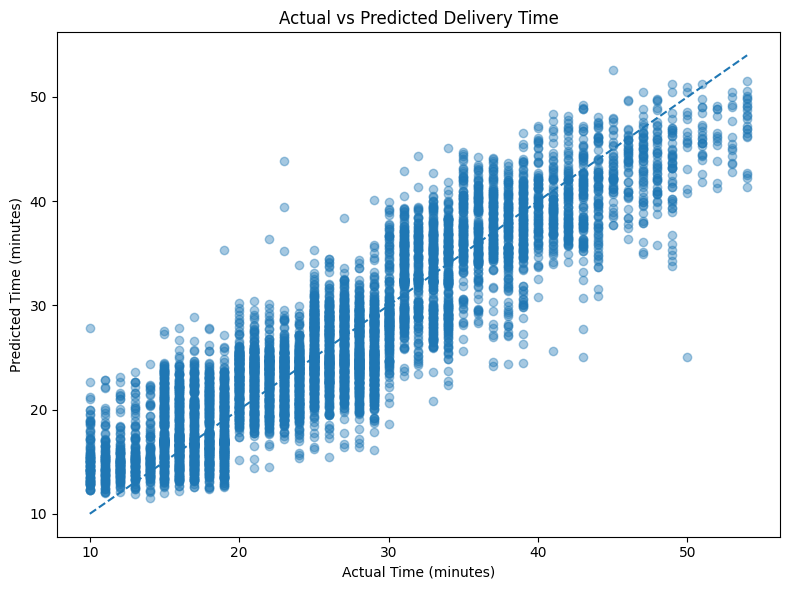

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Delivery Time")
plt.xlabel("Actual Time (minutes)")
plt.ylabel("Predicted Time (minutes)")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/actual_vs_predicted.png",
    dpi=300
)

plt.show()

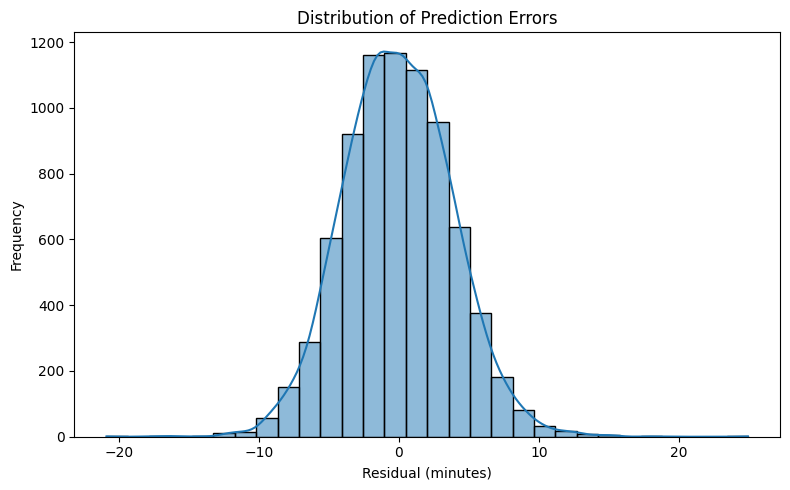

In [ ]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual (minutes)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/residual_distribution.png",
    dpi=300
)

plt.show()

In [ ]:
fitted_preprocessor = (
    travel_time_pipeline.named_steps["preprocessor"]
)

feature_names = fitted_preprocessor.get_feature_names_out()

importances = (
    travel_time_pipeline
    .named_steps["regressor"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(15))

,Feature,Importance
3,num__delivery_person_ratings,0.217755
15,cat__road_traffic_density_Low,0.117578
5,num__multiple_deliveries,0.113720
2,num__delivery_person_age,0.097816
11,cat__weather_conditions_Sunny,0.072619
4,num__vehicle_condition,0.071645
0,num__distance_km,0.069163
1,num__geo_distance_km,0.064354
8,cat__weather_conditions_Fog,0.046836
7,cat__weather_conditions_Cloudy,0.046703


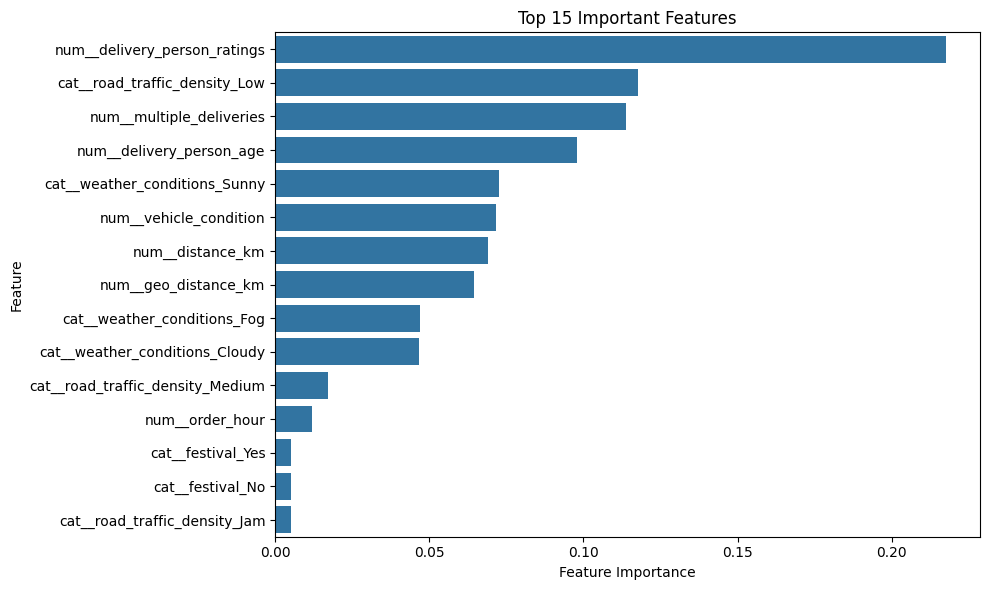

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/feature_importance.png",
    dpi=300
)

plt.show()

In [ ]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

comparison_df = pd.DataFrame({
    "Model": ["Mean Baseline", "Random Forest"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2": [baseline_r2, r2]
})

display(comparison_df)

comparison_df.to_csv(
    REPORT_PATH + "/travel_time_model_comparison.csv",
    index=False
)

,Model,MAE,RMSE,R2
0,Mean Baseline,7.430541,9.225740,-0.000096
1,Random Forest,3.088457,3.883072,0.822830


In [ ]:
MODEL_FILE = (
    MODEL_PATH + "/travel_time_prediction_model.pkl"
)

joblib.dump(
    travel_time_pipeline,
    MODEL_FILE
)

print("Model saved successfully!")
print(MODEL_FILE)

Model saved successfully!
/content/drive/MyDrive/Smart_Ride_Intelligence/models/travel_time/travel_time_prediction_model.pkl


In [ ]:
predictions_df.to_csv(
    REPORT_PATH + "/travel_time_test_predictions.csv",
    index=False
)

print("Test predictions saved!")

Test predictions saved!


In [ ]:
loaded_travel_model = joblib.load(
    MODEL_FILE
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [ ]:
sample_input = {}

for col in features:

    if col in numerical_features:

        sample_input[col] = X_train[col].median()

    else:

        sample_input[col] = X_train[col].mode().iloc[0]

sample_input = pd.DataFrame([sample_input])

display(sample_input)

,distance_km,geo_distance_km,delivery_person_age,delivery_person_ratings,vehicle_condition,multiple_deliveries,weather_conditions,road_traffic_density,type_of_order,type_of_vehicle,city,festival,order_hour,day_of_week
0,9.220368,9.220368,30.0,4.7,1.0,1.0,Fog,Low,Snack,motorcycle,Metropolitian,No,19.0,2


In [ ]:
predicted_time = loaded_travel_model.predict(
    sample_input
)[0]

print(
    f"Predicted delivery time: {predicted_time:.2f} minutes"
)

Predicted delivery time: 17.55 minutes


In [ ]:
custom_input = sample_input.copy()

if "distance_km" in custom_input.columns:
    custom_input.loc[0, "distance_km"] = 5.0

if "road_traffic_density" in custom_input.columns:
    custom_input.loc[0, "road_traffic_density"] = (
        "High"
    )

custom_prediction = loaded_travel_model.predict(
    custom_input
)[0]

print(
    f"Predicted delivery time: {custom_prediction:.2f} minutes"
)

Predicted delivery time: 28.25 minutes


In [ ]:
print("MODEL FILES")
print("--------------------")

for file in os.listdir(MODEL_PATH):
    print(file)

print("\nREPORT FILES")
print("--------------------")

for file in os.listdir(REPORT_PATH):
    print(file)

MODEL FILES
--------------------
travel_time_prediction_model.pkl

REPORT FILES
--------------------
missing_values_report.csv
delivery_time_distribution.png
distance_vs_delivery_time.png
traffic_vs_delivery_time.png
weather_vs_delivery_time.png
correlation_heatmap.png
travel_time_model_metrics.csv
actual_vs_predicted.png
residual_distribution.png
feature_importance.png
travel_time_model_comparison.csv
travel_time_test_predictions.csv
